In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

In [2]:
tumor = "t57"



In [3]:
#A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")

In [4]:
normal_info = A_df[["population", "normal_population"]].drop_duplicates()
normal_A = normal_info[normal_info["normal_population"] == True]["population"].values[0]

In [5]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A11
A121
A122
A21
A22


In [6]:
# First, load the real variants
tumor_variants_real = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep="\t")
#tumor_variants_real = tumor_variants_real[tumor_variants_real["alt_count"] > 0]

variants_with_vaf = pd.read_csv(f"../data/{tumor}/{tumor}.vaf.txt", sep = "\t")

# Then load pseudo variants
tumor_variants_pseudo = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep="\t")
#tumor_variants_pseudo = tumor_variants_pseudo[tumor_variants_pseudo["alt_count"] > 0]



In [7]:
high_freq_variants = variants_with_vaf[variants_with_vaf["tumor_vaf"]>=0.3]

In [8]:
low_freq_variants = variants_with_vaf[variants_with_vaf["tumor_vaf"]<0.05]

In [9]:
low_freq_variants.head()

,CHROM,POS,REF,ALT,tumor_vaf
4,chr10,447662,C,A,0.049645
8,chr10,956102,C,A,0.036232
9,chr10,1157858,G,T,0.030534
18,chr10,1792469,T,C,0.030534
35,chr10,5001772,G,A,0.033557


In [10]:
high_freq_variants.head()

,CHROM,POS,REF,ALT,tumor_vaf
10,chr10,1284155,G,A,0.453416
15,chr10,1670333,G,T,0.536585
20,chr10,1861512,T,C,0.313433
30,chr10,3348148,G,A,0.400000
48,chr10,6808292,G,C,0.328000


In [11]:
len(high_freq_variants), len(low_freq_variants)

(2966, 2143)

In [12]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,205327,TCTTGATTGGCCCGACA,0,0,0,1,1,0,1
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
3,chr10,205327,TATTTGTAAGCTGAATC,0,0,0,1,1,0,1
4,chr10,205327,GGAACATTGGCCACACA,0,0,0,1,1,0,1


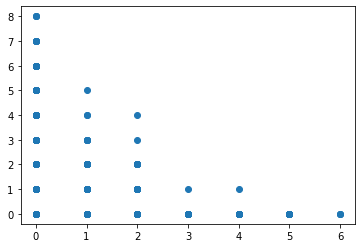

In [13]:
plt.plot(tumor_variants_real['alt_count'], tumor_variants_real['ref_count'], 'o')

In [14]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real[tumor_variants_real['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [15]:
# Create the summary table
variant_summary = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [16]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants
0,A11,393,24244,4939,392,24540,42,42
1,A121,136,7546,1655,136,7636,10,10
2,A122,210,12065,2551,210,12232,17,15
3,A21 (normal),1605,75673,3358,1276,75781,145,136
4,A22,86,4991,560,85,5066,6,6


In [17]:
variant_summary["variant_frequency"] = variant_summary["variant_observed"]/variant_summary["opportunities_for_variants"]
variant_summary["pseudo_frequency"] = variant_summary["pseudo_variant_observed"]/variant_summary["opportunities_for_pseudo"]
variant_summary["variant_per_cell"] = variant_summary["variant_observed"]/variant_summary["Num_Cells"]
variant_summary["pseudo_per_cell"] = variant_summary["pseudo_variant_observed"]/variant_summary["Num_Cells"]


In [18]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A11,393,24244,4939,392,24540,42,42,0.203721,0.001711,12.567430,0.106870
1,A121,136,7546,1655,136,7636,10,10,0.219321,0.001310,12.169118,0.073529
2,A122,210,12065,2551,210,12232,17,15,0.211438,0.001390,12.147619,0.080952
3,A21 (normal),1605,75673,3358,1276,75781,145,136,0.044375,0.001913,2.092212,0.090343
4,A22,86,4991,560,85,5066,6,6,0.112202,0.001184,6.511628,0.069767


In [19]:
# Above analysis for just the high frequency variants (variants defined by CHROM and POS)
high_freq_loci = high_freq_variants[['CHROM', 'POS']].values.tolist()
low_freq_loci = low_freq_variants[['CHROM', 'POS']].values.tolist()
# Restrict tumor_variants_real to just these loci
tumor_variants_real_hf = tumor_variants_real[tumor_variants_real[['chrom', 'pos']].apply(tuple, axis=1).isin([tuple(x) for x in high_freq_loci])]
tumor_variants_real_lf = tumor_variants_real[tumor_variants_real[['chrom', 'pos']].apply(tuple, axis=1).isin([tuple(x) for x in low_freq_loci])]

In [20]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real_hf[tumor_variants_real_hf['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [21]:
# Create the summary table
variant_summary_hf = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [22]:
variant_summary_hf["variant_frequency"] = variant_summary_hf["variant_observed"]/variant_summary_hf["opportunities_for_variants"]
variant_summary_hf["pseudo_frequency"] = variant_summary_hf["pseudo_variant_observed"]/variant_summary_hf["opportunities_for_pseudo"]
variant_summary_hf["variant_per_cell"] = variant_summary_hf["variant_observed"]/variant_summary_hf["Num_Cells"]
variant_summary_hf["pseudo_per_cell"] = variant_summary_hf["pseudo_variant_observed"]/variant_summary_hf["Num_Cells"]

In [23]:
variant_summary_hf

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A11,393,4675,2265,384,24540,42,42,0.484492,0.001711,5.763359,0.106870
1,A121,136,1446,754,131,7636,10,10,0.521438,0.001310,5.544118,0.073529
2,A122,210,2378,1229,206,12232,17,15,0.516821,0.001390,5.852381,0.080952
3,A21 (normal),1605,16106,176,155,75781,145,136,0.010928,0.001913,0.109657,0.090343
4,A22,86,1061,192,67,5066,6,6,0.180961,0.001184,2.232558,0.069767


In [24]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real_lf[tumor_variants_real_lf['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [25]:
# Create the summary table
variant_summary_lf = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [26]:
variant_summary_lf["variant_frequency"] = variant_summary_lf["variant_observed"]/variant_summary_lf["opportunities_for_variants"]
variant_summary_lf["pseudo_frequency"] = variant_summary_lf["pseudo_variant_observed"]/variant_summary_lf["opportunities_for_pseudo"]
variant_summary_lf["variant_per_cell"] = variant_summary_lf["variant_observed"]/variant_summary_lf["Num_Cells"]
variant_summary_lf["pseudo_per_cell"] = variant_summary_lf["pseudo_variant_observed"]/variant_summary_lf["Num_Cells"]

In [27]:
variant_summary_lf

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A11,393,4206,232,156,24540,42,42,0.055159,0.001711,0.590331,0.106870
1,A121,136,1252,87,58,7636,10,10,0.069489,0.001310,0.639706,0.073529
2,A122,210,2171,159,99,12232,17,15,0.073238,0.001390,0.757143,0.080952
3,A21 (normal),1605,12496,673,489,75781,145,136,0.053857,0.001913,0.419315,0.090343
4,A22,86,809,47,28,5066,6,6,0.058096,0.001184,0.546512,0.069767


In [28]:
tumor_info = tumor_variants_real[~tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]
normal_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]

In [29]:
tumor_variants_real_hf

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
66,chr10,1284155,GACGTGAATACTACTTC,2,0,0,0,0,2,2
67,chr10,1284155,TGAAACGGTGACTGAGT,1,0,0,0,0,1,1
68,chr10,1284155,GAGATATTGACTTGATA,0,0,0,1,1,0,1
69,chr10,1284155,GGGATCAAGCGTCTTAC,0,0,0,1,1,0,1
70,chr10,1284155,CCAGCTGACTGGCGTAG,0,0,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
160238,chrX,154197706,GACCCTATGCACGATCG,0,1,0,0,0,1,1
160239,chrX,154197706,TGAAGGTGCAGGTCATC,0,0,1,0,1,0,1
160240,chrX,154197706,GGCACTAGCGTTAGAGA,0,0,1,0,1,0,1
160241,chrX,154197706,TGCCAAGTAAACTGTAA,0,1,0,0,0,1,1


In [30]:
A_df.head()

,cell,population,normal_population
0,AAAACCAGCTTAGATAC,A11,False
1,AAAACCTAAACCAGACT,A11,False
2,AAAACCTAACCAACACA,A11,False
3,AAAACCTTGAGCATTGG,A11,False
4,AAAATGCTTCCAAGTAC,A11,False


In [31]:
cell_list = A_df["cell"].values.tolist()
tot_counter = Counter(tumor_variants_real_hf["cell_id"])
alt_counter = Counter(tumor_variants_real_hf[tumor_variants_real_hf["alt_count"]>0]["cell_id"])
for c in cell_list:
    if c not in tot_counter:
        tot_counter[c] = 0
    if c not in alt_counter:
        alt_counter[c] = 0

In [32]:
# vaf per cell
vaf_per_cell = {c: alt_counter[c] / tot_counter[c] if tot_counter[c] > 0 else 0 for c in cell_list}

(array([1.825e+03, 1.670e+02, 1.940e+02, 1.910e+02, 1.520e+02, 1.440e+02,
        9.300e+01, 7.200e+01, 7.200e+01, 3.800e+01, 3.100e+01, 2.000e+01,
        1.700e+01, 1.200e+01, 5.000e+00, 1.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 1.000e+00]),
 array([ 0.  ,  1.05,  2.1 ,  3.15,  4.2 ,  5.25,  6.3 ,  7.35,  8.4 ,
         9.45, 10.5 , 11.55, 12.6 , 13.65, 14.7 , 15.75, 16.8 , 17.85,
        18.9 , 19.95, 21.  ]),
 <BarContainer object of 20 artists>)

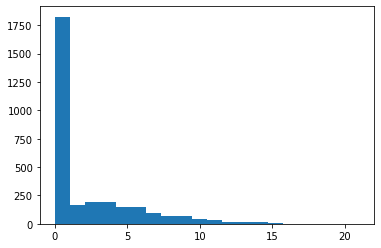

In [33]:
plt.hist(alt_counter.values(), bins = 20)

(array([ 84., 342., 228., 518., 250., 500., 222., 386., 161., 255., 184.,
         61., 107.,  37.,  54.,  19.,  26.,   7.,   5.,   4.]),
 array([ 0.  ,  1.55,  3.1 ,  4.65,  6.2 ,  7.75,  9.3 , 10.85, 12.4 ,
        13.95, 15.5 , 17.05, 18.6 , 20.15, 21.7 , 23.25, 24.8 , 26.35,
        27.9 , 29.45, 31.  ]),
 <BarContainer object of 20 artists>)

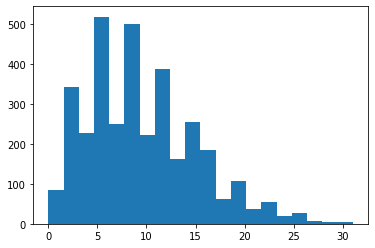

In [34]:
plt.hist(tot_counter.values(), bins = 20)

In [35]:
tumor_variants_real_hf["unique_loci"] = tumor_variants_real_hf["chrom"] + "_" + tumor_variants_real_hf["pos"].astype(str)

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [36]:
tumor_variants_real_hf

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count,unique_loci
66,chr10,1284155,GACGTGAATACTACTTC,2,0,0,0,0,2,2,chr10_1284155
67,chr10,1284155,TGAAACGGTGACTGAGT,1,0,0,0,0,1,1,chr10_1284155
68,chr10,1284155,GAGATATTGACTTGATA,0,0,0,1,1,0,1,chr10_1284155
69,chr10,1284155,GGGATCAAGCGTCTTAC,0,0,0,1,1,0,1,chr10_1284155
70,chr10,1284155,CCAGCTGACTGGCGTAG,0,0,0,1,1,0,1,chr10_1284155
...,...,...,...,...,...,...,...,...,...,...,...
160238,chrX,154197706,GACCCTATGCACGATCG,0,1,0,0,0,1,1,chrX_154197706
160239,chrX,154197706,TGAAGGTGCAGGTCATC,0,0,1,0,1,0,1,chrX_154197706
160240,chrX,154197706,GGCACTAGCGTTAGAGA,0,0,1,0,1,0,1,chrX_154197706
160241,chrX,154197706,TGCCAAGTAAACTGTAA,0,1,0,0,0,1,1,chrX_154197706


In [37]:
tumor_variants_real_hf.drop_duplicates(inplace=True)

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """Entry point for launching an IPython kernel.


In [38]:
#Counter(Counter(tumor_variants_real_hf[['unique_loci',"cell_id"]].apply(tuple, axis=1)).values())

In [39]:
alt_mat = tumor_variants_real_hf.pivot(index="unique_loci", columns="cell_id", values="alt_count").fillna(0)
ref_mat = tumor_variants_real_hf.pivot(index="unique_loci", columns="cell_id", values="ref_count").fillna(0)

In [40]:
#only pick "cell_ids" that are in the A_df
alt_mat = alt_mat[[c for c in alt_mat.columns if c in A_df["cell"].values]]
ref_mat = ref_mat[[c for c in ref_mat.columns if c in A_df["cell"].values]]

In [41]:
alt = alt_mat.to_numpy(dtype=np.int32)
ref = ref_mat.to_numpy(dtype=np.int32)

cell_ids = alt_mat.columns.to_numpy()
mutations = alt_mat.index.to_numpy()

In [42]:
import numpy as np

def gibbs_cluster(alt, ref, n_iter=200):
    """
    Unsupervised Gibbs clustering of cells using SNV counts.

    Parameters
    ----------
    alt : (M,N) numpy array
        Alternate read counts
    ref : (M,N) numpy array
        Reference read counts

    Returns
    -------
    z : (N,) array
        Cluster assignments (0 or 1)

    p1, p2 : (M,) arrays
        Estimated allele frequencies of the two clusters

    loglik : float
        Log-likelihood of the final clustering
    """

    M, N = alt.shape

    # Random initialization
    z = np.random.randint(0, 2, size=N)

    for iteration in range(n_iter):

        # -------------------------------------------------
        # Estimate allele frequencies of both clusters
        # -------------------------------------------------

        cluster1 = (z == 0)
        cluster2 = (z == 1)

        # Prevent empty clusters
        if cluster1.sum() == 0 or cluster2.sum() == 0:
            z = np.random.randint(0, 2, size=N)
            continue

        alt1 = alt[:, cluster1].sum(axis=1)
        ref1 = ref[:, cluster1].sum(axis=1)

        alt2 = alt[:, cluster2].sum(axis=1)
        ref2 = ref[:, cluster2].sum(axis=1)

        # Beta(1,1) posterior mean
        p1 = (alt1 + 1) / (alt1 + ref1 + 2)
        p2 = (alt2 + 1) / (alt2 + ref2 + 2)

        p1 = np.clip(p1, 1e-6, 1-1e-6)
        p2 = np.clip(p2, 1e-6, 1-1e-6)

        # -------------------------------------------------
        # Gibbs update
        # -------------------------------------------------

        for j in range(N):

            a = alt[:, j]
            r = ref[:, j]

            logL1 = np.sum(
                a*np.log(p1) +
                r*np.log(1-p1)
            )

            logL2 = np.sum(
                a*np.log(p2) +
                r*np.log(1-p2)
            )

            m = max(logL1, logL2)

            L1 = np.exp(logL1-m)
            L2 = np.exp(logL2-m)

            prob1 = L1/(L1+L2)

            z[j] = np.random.rand() < prob1

    # -------------------------------------------------
    # Compute final log-likelihood
    # -------------------------------------------------

    loglik = 0

    for j in range(N):

        a = alt[:, j]
        r = ref[:, j]

        if z[j] == 0:
            loglik += np.sum(a*np.log(p1) + r*np.log(1-p1))
        else:
            loglik += np.sum(a*np.log(p2) + r*np.log(1-p2))

    return z, p1, p2, loglik

In [44]:
z, p1, p2, loglik = gibbs_cluster(alt, ref)

In [45]:
A_df

,cell,population,normal_population
0,AAAACCAGCTTAGATAC,A11,False
1,AAAACCTAAACCAGACT,A11,False
2,AAAACCTAACCAACACA,A11,False
3,AAAACCTTGAGCATTGG,A11,False
4,AAAATGCTTCCAAGTAC,A11,False
...,...,...,...
2425,TTGGACGACTACCTAAG,A22,False
2426,TTGGGAGCCTCTCGTTC,A22,False
2427,TTTCGAAACAAGTGAGT,A22,False
2428,TTTCGATTGCTGTCACT,A22,False


In [47]:
z

array([0, 1, 0, ..., 1, 1, 0])

In [48]:
new_cluster_dict = dict(zip(cell_ids, z))

In [49]:
A_df["new_clusters"] = A_df["cell"].map(new_cluster_dict)

In [50]:
A_df

,cell,population,normal_population,new_clusters
0,AAAACCAGCTTAGATAC,A11,False,1.0
1,AAAACCTAAACCAGACT,A11,False,1.0
2,AAAACCTAACCAACACA,A11,False,1.0
3,AAAACCTTGAGCATTGG,A11,False,0.0
4,AAAATGCTTCCAAGTAC,A11,False,1.0
...,...,...,...,...
2425,TTGGACGACTACCTAAG,A22,False,0.0
2426,TTGGGAGCCTCTCGTTC,A22,False,0.0
2427,TTTCGAAACAAGTGAGT,A22,False,0.0
2428,TTTCGATTGCTGTCACT,A22,False,0.0


In [51]:
print(len(A_df[(A_df["new_clusters"] == 0) &  (A_df["normal_population"]== True)]))
print(len(A_df[(A_df["new_clusters"] == 1) &  (A_df["normal_population"]== True)]))
print(len(A_df[(A_df["new_clusters"] == 0) &  (A_df["normal_population"]== False)]))
print(len(A_df[(A_df["new_clusters"] == 1) &  (A_df["normal_population"]== False)]))

1555
43
164
661


In [53]:
# First split
z1, p11, p12, loglik1 = gibbs_cluster(alt, ref)

# Separate the cells
cells_A = np.where(z1 == 0)[0]
cells_B = np.where(z1 == 1)[0]

# Subset the matrices
alt_A = alt[:, cells_A]
ref_A = ref[:, cells_A]

alt_B = alt[:, cells_B]
ref_B = ref[:, cells_B]

# Second split on Cluster A
zA, pA1, pA2, loglikA = gibbs_cluster(alt_A, ref_A)

# Second split on Cluster B
zB, pB1, pB2, loglikB = gibbs_cluster(alt_B, ref_B)

In [63]:
loglik1, loglikA, loglikB

(-31090.380659595507, -8093.253502260929, -13444.071758381044)

In [54]:
Counter(z1)

Counter({1: 1712, 0: 711})

In [55]:
Counter(zA)

Counter({1: 369, 0: 342})

In [56]:
Counter(zB)

Counter({0: 1573, 1: 139})

In [57]:
A_df

,cell,population,normal_population,new_clusters
0,AAAACCAGCTTAGATAC,A11,False,1.0
1,AAAACCTAAACCAGACT,A11,False,1.0
2,AAAACCTAACCAACACA,A11,False,1.0
3,AAAACCTTGAGCATTGG,A11,False,0.0
4,AAAATGCTTCCAAGTAC,A11,False,1.0
...,...,...,...,...
2425,TTGGACGACTACCTAAG,A22,False,0.0
2426,TTGGGAGCCTCTCGTTC,A22,False,0.0
2427,TTTCGAAACAAGTGAGT,A22,False,0.0
2428,TTTCGATTGCTGTCACT,A22,False,0.0


In [61]:
comparison_A = pd.DataFrame({
    "cell": cell_ids[cells_A],
    "gibbs_cluster": zA
}).merge(A_df, on="cell")

comparison_A["gibbs_cluster"] = "A"+ comparison_A["gibbs_cluster"].apply(str)

comparison_B = pd.DataFrame({
    "cell": cell_ids[cells_B],
    "gibbs_cluster": zB
}).merge(A_df, on="cell")
comparison_B["gibbs_cluster"] = "B"+ comparison_B["gibbs_cluster"].apply(str)

comparison = pd.concat([comparison_A, comparison_B], axis=0)

In [62]:
pd.crosstab(
    comparison["population"],
    comparison["gibbs_cluster"]
)

gibbs_cluster,A0,A1,B0,B1
population,,,,
A11,167,179,19,28
A121,54,63,9,10
A122,97,95,6,12
A21,14,23,1487,74
A22,10,9,52,15


In [60]:
stop

NameError: name 'stop' is not defined

In [ ]:
pos_groups = tumor_info.groupby(["chrom", "pos"])
pos_groups_normal = normal_info.groupby(["chrom", "pos"])

In [ ]:
tumor_info

In [ ]:
#unique_positions = high_freq_loci
unique_positions = low_freq_loci

In [ ]:
tumor_info

In [ ]:
# p = unique_positions[0]
# df = pos_groups.get_group((p[0], p[1]))


In [ ]:
row_list = []
for p in unique_positions:
    try:
        df = pos_groups.get_group((p[0], p[1]))
        r_count = df["ref_count"].sum()
        a_count = df["alt_count"].sum()
        tot = df["total_count"].sum()
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": r_count,
            "alt_count": a_count,
            "total_count": tot,
            "variant_frequency": a_count / tot
        })
    except:
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": 0,
            "alt_count": 0,
            "total_count": 0,
            "variant_frequency": None
        })

tumor_variant_summary = pd.DataFrame(row_list)

In [ ]:
row_list = []
for p in unique_positions:
    try:
        df = pos_groups_normal.get_group((p[0], p[1]))
        r_count = df["ref_count"].sum()
        a_count = df["alt_count"].sum()
        tot = df["total_count"].sum()
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": r_count,
            "alt_count": a_count,
            "total_count": tot,
            "variant_frequency": a_count / tot
        })
    except:
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": 0,
            "alt_count": 0,
            "total_count": 0,
            "variant_frequency": None
        })

normal_variant_summary = pd.DataFrame(row_list)

In [ ]:
tumor_variant_summary.head()

In [ ]:
tumor_variant_summary_hc = tumor_variant_summary[tumor_variant_summary["total_count"] >= 10]
normal_variant_summary_hc = normal_variant_summary[normal_variant_summary["total_count"] >= 10]

In [ ]:
normal_variant_summary.head()

In [ ]:
#merge tumor and normal variant summaries
merged_variant_summary = tumor_variant_summary.merge(normal_variant_summary, on=["chrom", "pos"], suffixes=("_tumor", "_normal"))

In [ ]:
merged_variant_summary.dropna(inplace=True)

In [ ]:
#merged_variant_summary[["chrom", "pos", "alt_count_tumor", "total_count_tumor","alt_count_normal", "total_count_normal"]].to_csv(f"../data/{tumor}/{tumor}_variant_summary_for_Mike.txt", sep="\t", index=False)

In [ ]:
merged_variant_summary["total"] = merged_variant_summary["total_count_tumor"] + merged_variant_summary["total_count_normal"]

In [ ]:
merged_variant_summary.head()

In [ ]:

merged_variant_summary = merged_variant_summary[merged_variant_summary["total"] >= 10]

In [ ]:
merged_variant_summary

In [ ]:
plt.scatter(merged_variant_summary["variant_frequency_normal"], merged_variant_summary["variant_frequency_tumor"], alpha=0.5)
plt.xlabel("Normal Variant Frequency")
plt.ylabel("Tumor Variant Frequency")
plt.title("Variant Frequencies: Tumor vs Normal")
plt.show()

In [ ]:
merged_variant_summary["variant_frequency_normal"].hist(bins=50)
plt.title("Frequency Distribution in Normal")
plt.show()
merged_variant_summary["variant_frequency_tumor"].hist(bins=50)
plt.title("Frequency Distribution in Tumor")
plt.show()

In [ ]:
merged_variant_summary[["variant_frequency_normal", "variant_frequency_tumor"]].corr()

In [ ]:
tumor_variants_real_lf.head()

In [ ]:
print(((merged_variant_summary["variant_frequency_normal"]==0) & (merged_variant_summary["variant_frequency_tumor"]==0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]!=0) & (merged_variant_summary["variant_frequency_tumor"]==0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]==0) & (merged_variant_summary["variant_frequency_tumor"]!=0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]!=0) & (merged_variant_summary["variant_frequency_tumor"]!=0)).sum())




In [ ]:
non_zero_somewhere = merged_variant_summary[(merged_variant_summary["variant_frequency_normal"]!=0) | (merged_variant_summary["variant_frequency_tumor"]!=0)]

In [ ]:
non_zero_somewhere[["variant_frequency_normal", "variant_frequency_tumor"]].corr()

In [ ]:
info_df_grps_dict = {}
for pop in A_dict.keys():
    cells = A_dict[pop]['cells']
    df = tumor_variants_real_lf[tumor_variants_real_lf['cell_id'].isin(cells)]
    info_df_grps_dict[pop] = df




In [ ]:
variant_summary_df_dict = {}
for pop in info_df_grps_dict.keys():
    df = info_df_grps_dict[pop]
    pos_groups = df.groupby(['chrom', 'pos'])
    
    row_list = []
    for p in low_freq_loci:
        try:
            group_df = pos_groups.get_group((p[0], p[1]))
            r_count = group_df["ref_count"].sum()
            a_count = group_df["alt_count"].sum()
            tot = group_df["total_count"].sum()
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": r_count,
                "alt_count": a_count,
                "total_count": tot,
                "variant_frequency": a_count / tot
            })
        except:
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": 0,
                "alt_count": 0,
                "total_count": 0,
                "variant_frequency": None
            })
    
    variant_summary_df_dict[pop] = pd.DataFrame(row_list)


In [ ]:
# merge all population variant summaries into a single dataframe
merged_pop_variant_summary = None
for pop in variant_summary_df_dict.keys():
    df = variant_summary_df_dict[pop][["chrom", "pos","total_count", "alt_count"]]
    df = df.rename(columns={"total_count": f"total_count_{pop}", "alt_count": f"alt_count_{pop}"})
    if merged_pop_variant_summary is None:
        merged_pop_variant_summary = df
    else:
        merged_pop_variant_summary = merged_pop_variant_summary.merge(df, on=["chrom", "pos"], how="outer") 

In [ ]:
merged_pop_variant_summary["total_count"] = merged_pop_variant_summary[[col for col in merged_pop_variant_summary.columns if col.startswith("total_count_")]].sum(axis=1)

In [ ]:
merged_pop_variant_summary.head()

In [ ]:
#merged_pop_variant_summary = merged_pop_variant_summary[merged_pop_variant_summary["total_count"] >= 10]

In [ ]:
merged_pop_variant_summary.head()

In [ ]:
tumor_variant_summary[tumor_variant_summary["total_count"] > 5]["variant_frequency"].hist(bins=50) 

In [ ]:
tumor_variant_summary[(tumor_variant_summary["variant_frequency"]!=0) & (tumor_variant_summary["total_count"] > 5)]["variant_frequency"].hist(bins=50)

In [ ]:
well_covered_non_zero_variants = tumor_variant_summary[(tumor_variant_summary["total_count"] > 20) & (tumor_variant_summary["variant_frequency"] > 0)]

In [ ]:
tumor_clones = [ t for t in A_dict.keys() if t != normal_A ]

In [ ]:
t = tumor_clones[0]

In [ ]:
tumor_variants_real.head()

In [ ]:
unique_positions = well_covered_non_zero_variants[["chrom", "pos"]].drop_duplicates().values.tolist()

In [ ]:
vaf_list = []

for t in A_dict.keys():
    # Get variant data for this tumor clone

    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    #unique_positions = tumor_clone_info[["chrom", "pos"]].drop_duplicates().values.tolist()
    
    vaf_spread = []
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    
    vaf_list.append(vaf_spread)  # This should be OUTSIDE the position loop

# Now plot
plt.figure(figsize=(10, 6))
plt.boxplot(vaf_list, labels=A_dict.keys())
plt.ylabel("VAF")
plt.xlabel("Tumor Clone")
plt.title("VAF Spread Across Tumor Clones")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()
# plt.xlabel("VAF")
# plt.ylabel("Frequency")
# plt.title("VAF Distribution Across Tumor Clones")
# plt.legend()
# plt.show()

In [ ]:
well_covered = tumor_variant_summary[(tumor_variant_summary["alt_count"] > 3) & (tumor_variant_summary["total_count"] > 10) ]

In [ ]:
well_covered["variant_frequency"].hist(bins=50)

In [ ]:
unique_positions = well_covered[["chrom", "pos"]].drop_duplicates().values.tolist()
vaf_list = []
row_list = []
for t in A_dict.keys():
    # Get variant data for this tumor clone
    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    vaf_spread = []
    var_count = 0
    tot_count = 0
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            var_count += a_count
            tot_count += tot
            
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    row_list.append({"tumor_clone": t, "var_count": var_count, "tot_count": tot_count, "vaf": var_count/tot_count})
    
    vaf_list.append(vaf_spread)  
    
    

In [ ]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()

In [ ]:
pd.DataFrame(row_list)

In [ ]:
len(unique_positions)

In [ ]:
len(high_freq_loci)

In [ ]:
info_df_grps_dict = {}
for pop in A_dict.keys():
    cells = A_dict[pop]['cells']
    df = tumor_variants_real_hf[tumor_variants_real_hf['cell_id'].isin(cells)]
    info_df_grps_dict[pop] = df

In [ ]:
variant_summary_df_dict = {}
for pop in info_df_grps_dict.keys():
    df = info_df_grps_dict[pop]
    pos_groups = df.groupby(['chrom', 'pos'])
    
    row_list = []
    for p in high_freq_loci:
        try:
            group_df = pos_groups.get_group((p[0], p[1]))
            r_count = group_df["ref_count"].sum()
            a_count = group_df["alt_count"].sum()
            tot = group_df["total_count"].sum()
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": r_count,
                "alt_count": a_count,
                "total_count": tot,
                "variant_frequency": a_count / tot
            })
        except:
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": 0,
                "alt_count": 0,
                "total_count": 0,
                "variant_frequency": None
            })
    
    variant_summary_df_dict[pop] = pd.DataFrame(row_list)


In [ ]:
# merge all population variant summaries into a single dataframe
merged_pop_variant_summary = None
for pop in variant_summary_df_dict.keys():
    df = variant_summary_df_dict[pop][["chrom", "pos","total_count", "alt_count"]]
    df = df.rename(columns={"total_count": f"total_count_{pop}", "alt_count": f"alt_count_{pop}"})
    if merged_pop_variant_summary is None:
        merged_pop_variant_summary = df
    else:
        merged_pop_variant_summary = merged_pop_variant_summary.merge(df, on=["chrom", "pos"], how="outer") 

In [ ]:
merged_pop_variant_summary["total_count"] = merged_pop_variant_summary[[col for col in merged_pop_variant_summary.columns if col.startswith("total_count_")]].sum(axis=1)

In [ ]:
merged_pop_variant_summary = merged_pop_variant_summary[merged_pop_variant_summary["total_count"] != 0]

In [ ]:
merged_pop_variant_summary["alt_total"] = merged_pop_variant_summary[[col for col in merged_pop_variant_summary.columns if col.startswith("alt_count_")]].sum(axis=1)

In [ ]:
merged_pop_variant_summary.to_csv(f"../data/{tumor}/{tumor}_high_freq_variant_summary_by_population.txt", sep="\t", index=False)